# Modelos supervisionados: o quanto a divisão aleatória engana

Este notebook analisa os treinos da etapa 2: XGBoost e Random Forest nos protocolos P0 (divisão
aleatória) e P1 (divisão temporal), mais as variações da porta de destino e de profundidade das
árvores. A pergunta é quanto o P0 infla os resultados e **por quê**.

Pelos ADRs, a porta de destino fica fora do modelo
([0004](../docs/adr/0004-porta-de-destino.md)), e Heartbleed e Infiltration ficam fora do
multiclasse ([0003](../docs/adr/0003-familias-e-classes-raras.md)). Os rótulos são os publicados
([0001](../docs/adr/0001-versao-do-conjunto.md)), mesmo quando parecem errados: a seção 4 mostra a
métrica com e sem os casos suspeitos, para separar erro do modelo de erro do rótulo.

**Como rodar:** depois de `nids data clean` e `nids data split`, treine cada experimento com
`uv run nids train configs/experiments/<nome>.yaml`. O notebook lê os modelos de `models/` e as
métricas de `reports/supervised.json`, sem treinar nada.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display

from nids import schema
from nids.evaluation import evaluate
from nids.models.registry import load_model
from nids.models.supervised import EXCLUDED_FAMILIES

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "reports" / "figures"
SPLITS = ROOT / "data" / "processed"
RESULTS = json.loads((ROOT / "reports" / "supervised.json").read_text(encoding="utf-8"))
PROTOCOL = {"random": "P0", "temporal": "P1", "unseen": "P2"}
MAIN = ["xgb_random", "xgb_temporal", "rf_random", "rf_temporal"]
FAMILIES = [f for f in schema.FAMILIES if f not in EXCLUDED_FAMILIES]

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 110,
        "font.size": 9,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_columns", 20, "display.width", 140)


def save(fig, name):
    fig.savefig(FIGURES / f"supervisionado_{name}.png", bbox_inches="tight")


def test_set(protocol):
    df = pd.read_parquet(SPLITS / protocol / "test.parquet")
    return df[~df[schema.FAMILY].isin(EXCLUDED_FAMILIES)].reset_index(drop=True)


def summary(names):
    rows = {
        name: {
            "modelo": RESULTS[name]["model"],
            "protocolo": PROTOCOL[RESULTS[name]["protocol"]],
            "macro-F1 validação": RESULTS[name]["val"]["macro_f1"],
            "macro-F1 teste": RESULTS[name]["test"]["macro_f1"],
        }
        for name in names
    }
    return pd.DataFrame(rows).T

## 1. Resultado principal

Mesmo modelo, mesmos hiperparâmetros, mesmos dados limpos: só muda a forma de dividir.

In [2]:
display(summary(MAIN))

,modelo,protocolo,macro-F1 validação,macro-F1 teste
xgb_random,xgboost,P0,0.964011,0.957158
xgb_temporal,xgboost,P1,0.96201,0.800951
rf_random,random_forest,P0,0.85833,0.856998
rf_temporal,random_forest,P1,0.855284,0.813816


**Leitura.** No teste, o XGBoost cai de 0,957 no P0 para 0,801 no P1: a divisão aleatória infla a
macro-F1 em 15,6 pontos. No P1, a validação (0,962) parece tão boa quanto o P0, e só o teste
revela a queda, porque é o teste que fica no fim de cada dia, depois do período visto no treino. O
Random Forest perde menos (0,857 para 0,814), mas parte de um patamar mais baixo, como mostra a
próxima seção.

## 2. Onde está a queda

,xgb_random (P0),xgb_temporal (P1),rf_random (P0),rf_temporal (P1)
BENIGN,0.999,0.982,0.995,0.993
BruteForce,0.998,0.988,0.983,0.964
DoS,0.998,0.983,0.994,0.952
WebAttack,0.963,0.866,0.842,0.828
Bot,0.744,0.000,0.189,0.000
PortScan,0.997,0.979,0.997,0.963
DDoS,1.000,0.808,0.999,0.998


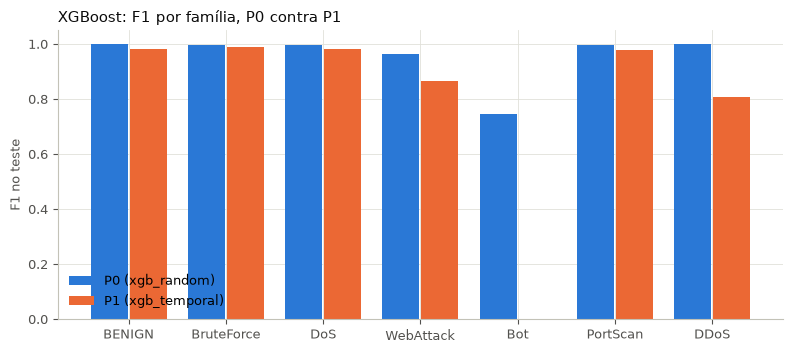

In [3]:
per_family = pd.DataFrame(
    {
        f"{name} ({PROTOCOL[RESULTS[name]['protocol']]})": {
            f: RESULTS[name]["test"]["per_class"][f]["f1"] for f in FAMILIES
        }
        for name in MAIN
    }
)
display(per_family.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(FAMILIES))
for offset, name, color in [(-0.2, "xgb_random", BLUE), (0.2, "xgb_temporal", ORANGE)]:
    label = f"{PROTOCOL[RESULTS[name]['protocol']]} ({name})"
    values = [RESULTS[name]["test"]["per_class"][f]["f1"] for f in FAMILIES]
    ax.bar(x + offset, values, width=0.38, color=color, label=label)
ax.set_xticks(x, FAMILIES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 no teste")
ax.set_title("XGBoost: F1 por família, P0 contra P1", loc="left", color=INK)
ax.legend(loc="lower left")
fig.tight_layout()
save(fig, "f1_por_familia")
plt.show()

**Leitura.** A queda não é espalhada. Ela se concentra em três famílias: **Bot** (de 0,74 para
zero), **DDoS** (de 1,00 para 0,81) e **WebAttack** (de 0,96 para 0,87). As duas próximas seções
investigam as duas primeiras.

## 3. Bot: um comportamento que o treino não viu

In [4]:
model_p1 = load_model(ROOT / "models" / "xgb_temporal")
test_p1 = test_set("temporal")
test_p1["pred"] = model_p1.predict(test_p1)
train_p1 = pd.read_parquet(SPLITS / "temporal" / "train.parquet")

rows = {}
for part, df in [("treino", train_p1), ("teste", test_p1)]:
    bot = df[df[schema.FAMILY] == "Bot"]
    rows[part] = {
        "fluxos": len(bot),
        "primeiro": f"{bot[schema.TIMESTAMP].min():%H:%M}",
        "último": f"{bot[schema.TIMESTAMP].max():%H:%M}",
        "% para a porta 8080": round(100 * (bot["destination_port"] == 8080).mean()),
    }
display(pd.DataFrame(rows).T)
bot_test = test_p1[test_p1[schema.FAMILY] == "Bot"]
print("fluxos de Bot do teste classificados como:", bot_test["pred"].value_counts().to_dict())

,fluxos,primeiro,último,% para a porta 8080
treino,1172,09:34,10:48,52
teste,391,11:26,12:59,100


fluxos de Bot do teste classificados como: {'BENIGN': 391}


**Leitura.** O teste do P1 pega os últimos 20 % dos fluxos de Bot no tempo, de 11:26 a 12:59. Pela
agenda oficial, o ataque terminou às 11:02 (análise exploratória, seção 2). Os fluxos rotulados
como Bot depois disso vão todos para a porta 8080 do servidor de comando, enquanto no treino só
metade vai. O modelo nunca viu esse comportamento e classifica os 391 como normais. No P0, fluxos
do mesmo período caem também no treino, e o problema some.

Os pares de IP do Bot têm a mesma direção no treino e no teste (máquina infectada para o servidor
de comando), então a falha não vem da direção dos fluxos.

## 4. DDoS: o modelo acerta, o rótulo erra

Os rótulos do CIC-IDS2017 marcam como ataque só a direção atacante → vítima. As respostas da vítima
ao atacante ficam rotuladas como normais. Para medir o efeito, chamo de **fluxo de resposta** todo
fluxo rotulado como normal cujo par de IPs (origem → destino) é o inverso de um par de ataque do
mesmo dia.

In [5]:
flows = pd.read_parquet(ROOT / "data" / "interim" / "flows.parquet")
attacks = flows[flows[schema.FAMILY] != schema.BENIGN]
attack_pairs = set(
    zip(
        attacks[schema.DAY].astype(str),
        attacks["source_ip"],
        attacks["destination_ip"],
        strict=True,
    )
)


def is_response(df):
    reverse = zip(df[schema.DAY].astype(str), df["destination_ip"], df["source_ip"], strict=True)
    inverse = np.fromiter((pair in attack_pairs for pair in reverse), bool, len(df))
    return inverse & (df[schema.FAMILY] == schema.BENIGN).to_numpy()


response = is_response(flows)
pairs = flows["source_ip"] + " → " + flows["destination_ip"]
print(f"fluxos de resposta no conjunto limpo: {response.sum()}")
display(pairs[response].value_counts().head(4).to_frame("fluxos"))

false_ddos = (test_p1["pred"] == "DDoS") & (test_p1[schema.FAMILY] == schema.BENIGN)
print(
    f"falsos DDoS no teste do P1: {false_ddos.sum()}, dos quais "
    f"{(false_ddos & is_response(test_p1)).sum()} são fluxos de resposta"
)

fluxos de resposta no conjunto limpo: 46627


,fluxos
192.168.10.50 → 172.16.0.1,42519
192.168.10.51 → 172.16.0.1,3125
192.168.10.15 → 205.174.165.73,278
192.168.10.8 → 205.174.165.73,278


falsos DDoS no teste do P1: 12095, dos quais 12085 são fluxos de resposta


In [6]:
rows = {}
for name in MAIN:
    model = load_model(ROOT / "models" / name)
    df = test_set(RESULTS[name]["protocol"])
    predicted = model.predict(df)
    keep = ~is_response(df)
    actual = df[schema.FAMILY].astype(str)
    clean = evaluate(actual[keep], predicted[keep])
    rows[name] = {
        "protocolo": PROTOCOL[RESULTS[name]["protocol"]],
        "macro-F1, todos": evaluate(actual, predicted)["macro_f1"],
        "macro-F1, sem respostas": clean["macro_f1"],
        "respostas removidas": int((~keep).sum()),
        "F1 do Bot, sem respostas": clean["per_class"]["Bot"]["f1"],
        "F1 do DDoS, sem respostas": clean["per_class"]["DDoS"]["f1"],
    }
display(pd.DataFrame(rows).T.round(3))

,protocolo,"macro-F1, todos","macro-F1, sem respostas",respostas removidas,"F1 do Bot, sem respostas","F1 do DDoS, sem respostas"
xgb_random,P0,0.957158,0.979503,9371,0.898345,0.999785
xgb_temporal,P1,0.800951,0.8306,31612,0.0,0.998984
rf_random,P0,0.856998,0.858436,9371,0.19801,0.998595
rf_temporal,P1,0.813816,0.813734,31612,0.0,0.997988


**Leitura.** São 46.627 fluxos de resposta, quase todos da vítima do DDoS e do PortScan
(192.168.10.50) para o atacante. No teste do P1, praticamente todos os falsos DDoS são respostas: o
modelo reconhece tráfego do ataque que o conjunto chama de normal. No P0, essas respostas caem também
no treino, rotuladas como normais, e o modelo aprende o rótulo errado.

Sem as respostas, o XGBoost sobe para 0,980 no P0 e 0,831 no P1, e o DDoS do P1 volta a 0,999. A
diferença entre os protocolos continua em cerca de 15 pontos, agora explicada pelo Bot e pelos
ataques web. Ou seja, o erro de rótulo existe, mas não é ele que infla o P0.

## 5. Porta de destino ([ADR 0004](../docs/adr/0004-porta-de-destino.md))

In [7]:
display(summary(["xgb_temporal", "xgb_temporal_porta"]))

,modelo,protocolo,macro-F1 validação,macro-F1 teste
xgb_temporal,xgboost,P1,0.96201,0.800951
xgb_temporal_porta,xgboost,P1,0.969107,0.804521


**Leitura.** Sozinha, a porta chega a macro-F1 de 0,33 (análise exploratória, seção 6). Somada aos
outros atributos, quase não muda nada (0,801 para 0,805 no teste): a informação dela já está no
resto. Tirá-la do modelo, como decidido no ADR 0004, não custa desempenho.

## 6. Sensibilidade aos hiperparâmetros

Os hiperparâmetros são fixos, sem ajuste fino. Para checar se a conclusão depende deles, o XGBoost
foi treinado também com árvores mais rasas (profundidade 4) e mais profundas (12) do que o padrão
(8), nos dois protocolos.

In [8]:
variants = {"raso": 4, "padrão": 8, "profundo": 12}
rows = {}
for label, depth in variants.items():
    for protocol in ("random", "temporal"):
        name = f"xgb_{protocol}" + ("" if label == "padrão" else f"_{label}")
        rows[(label, depth, PROTOCOL[protocol])] = {
            "macro-F1 validação": RESULTS[name]["val"]["macro_f1"],
            "macro-F1 teste": RESULTS[name]["test"]["macro_f1"],
        }
sensitivity = pd.DataFrame(rows).T.rename_axis(["variação", "profundidade", "protocolo"])
display(sensitivity.round(3))

macro-F1 validação  macro-F1 teste
variação profundidade protocolo                                    
raso     4            P0                      0.944           0.941
                      P1                      0.946           0.812
padrão   8            P0                      0.964           0.957
                      P1                      0.962           0.801
profundo 12           P0                      0.964           0.960
                      P1                      0.966           0.802

**Leitura.** A diferença entre os protocolos aparece nas três profundidades: 12,8 pontos com
árvores rasas, 15,6 no padrão e 15,8 com árvores profundas. Árvores mais profundas melhoram o P0
(de 0,941 para 0,960), mas não o P1 (de 0,812 para 0,802): a profundidade extra serve para decorar
detalhes que o P0 reencontra no teste, não para generalizar.

Se a profundidade fosse escolhida pela validação do P1, como manda o protocolo, a escolha seria a
maior (0,966), com 0,802 no teste. O ajuste fino não resolve o problema, porque a validação do P1
fica antes do fim de cada dia e não vê a mudança que acontece depois.

## 7. Heartbleed e Infiltration ([ADR 0003](../docs/adr/0003-familias-e-classes-raras.md))

As duas famílias ficaram fora do treino. Por isso, todos os seus fluxos são inéditos para os modelos
e podem ser usados na avaliação, sem vazamento. Como o modelo não conhece essas classes, a pergunta é
binária: o fluxo foi apontado como algum ataque?

In [9]:
rare = flows[flows[schema.FAMILY].isin(EXCLUDED_FAMILIES)]
rows = {}
for name in MAIN:
    predicted = pd.Series(load_model(ROOT / "models" / name).predict(rare), index=rare.index)
    for family in EXCLUDED_FAMILIES:
        mine = predicted[rare[schema.FAMILY] == family]
        rows.setdefault(name, {})[family] = f"{(mine != schema.BENIGN).sum()} de {len(mine)}"
display(pd.DataFrame(rows).T)

,Heartbleed,Infiltration
xgb_random,6 de 11,1 de 36
xgb_temporal,0 de 11,1 de 36
rf_random,0 de 11,0 de 36
rf_temporal,0 de 11,0 de 36


**Leitura.** Praticamente nada é detectado. O melhor caso é o XGBoost do P0, que aponta 6 dos 11
fluxos de Heartbleed (como DoS) e 1 dos 36 de Infiltration. É a limitação de fundo do modelo
supervisionado: um ataque de natureza nova tende a ser classificado como normal. É essa lacuna que
os detectores de anomalia da etapa 3 vão tentar cobrir.

## 8. Checagem de atalhos com SHAP

O XGBoost calcula a contribuição de cada atributo para cada previsão (valores SHAP). A figura mostra
a contribuição média, em valor absoluto, numa amostra do teste do P1.

três primeiros: 32% da contribuição total


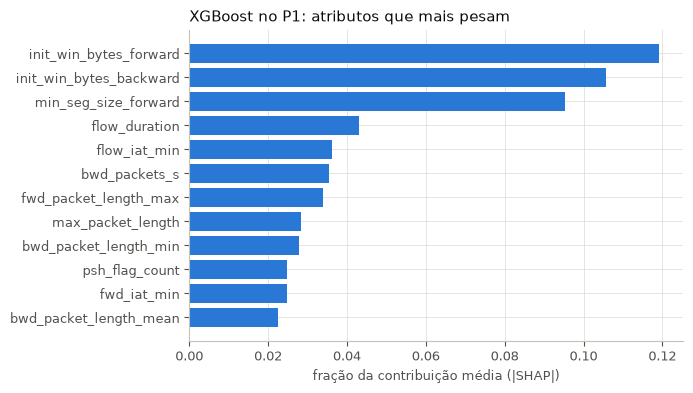

In [10]:
sample = test_p1.sample(20_000, random_state=0)
matrix = xgb.DMatrix(sample[model_p1.metadata["features"]])
contributions = model_p1.estimator.get_booster().predict(matrix, pred_contribs=True)
mean_abs = np.abs(contributions[:, :, :-1]).mean(axis=(0, 1))  # sem a coluna do viés
share = pd.Series(mean_abs, index=model_p1.metadata["features"])
share = (share / share.sum()).sort_values(ascending=False)
print(f"três primeiros: {share.iloc[:3].sum():.0%} da contribuição total")

fig, ax = plt.subplots(figsize=(7, 4))
top = share.iloc[:12][::-1]
ax.barh(top.index, top.to_numpy(), color=BLUE)
ax.set_xlabel("fração da contribuição média (|SHAP|)")
ax.set_title("XGBoost no P1: atributos que mais pesam", loc="left", color=INK)
fig.tight_layout()
save(fig, "shap")
plt.show()

**Leitura.** Os três atributos que mais pesam são a janela TCP inicial nos dois sentidos e
`min_seg_size_forward`, e juntos somam cerca de um terço da contribuição. Esses valores são
definidos pelo sistema operacional de cada máquina, não pelo comportamento do ataque. No
laboratório, os ataques saem de poucas máquinas, então o modelo pode estar reconhecendo a
**máquina do atacante**, e não o ataque. É um atalho do mesmo tipo da porta de destino, porém mais
sutil. A próxima seção testa a hipótese.

## 9. Teste da hipótese: sem os atributos da janela TCP

O XGBoost foi treinado de novo, nos dois protocolos, sem `init_win_bytes_forward`,
`init_win_bytes_backward` e `min_seg_size_forward`, com todo o resto igual.

In [11]:
pairs = [("xgb_random", "xgb_random_sem_tcp"), ("xgb_temporal", "xgb_temporal_sem_tcp")]
columns = {}
for with_tcp, without_tcp in pairs:
    protocol = PROTOCOL[RESULTS[with_tcp]["protocol"]]
    for label, name in [("com", with_tcp), ("sem", without_tcp)]:
        f1 = {f: RESULTS[name]["test"]["per_class"][f]["f1"] for f in FAMILIES}
        columns[(protocol, label)] = f1 | {"macro-F1": RESULTS[name]["test"]["macro_f1"]}
display(pd.DataFrame(columns).round(3))

P0            P1       
              com    sem    com    sem
BENIGN      0.999  0.976  0.982  0.961
BruteForce  0.998  0.686  0.988  0.695
DoS         0.998  0.991  0.983  0.940
WebAttack   0.963  0.114  0.866  0.105
Bot         0.744  0.067  0.000  0.000
PortScan    0.997  0.997  0.979  0.967
DDoS        1.000  0.999  0.808  0.833
macro-F1    0.957  0.690  0.801  0.643

Uma queda grande não prova um atalho: o atributo pode ser informativo de verdade. O que separa as
duas coisas é se os ataques carregam uma "impressão digital" de máquina. A tabela compara, para as
três famílias que mais caem, o valor de janela mais comum nos ataques com o tráfego normal que vai
para as mesmas portas.

In [12]:
rows = {}
for family, ports in [("WebAttack", [80]), ("BruteForce", [21, 22]), ("Bot", [8080])]:
    attack = flows[flows[schema.FAMILY] == family]
    window = attack["init_win_bytes_forward"].value_counts(normalize=True)
    normal = flows[(flows[schema.FAMILY] == schema.BENIGN) & flows["destination_port"].isin(ports)]
    rows[family] = {
        "IPs de origem": attack["source_ip"].nunique(),
        "janela mais comum": int(window.index[0]),
        "% dos ataques": round(100 * window.iloc[0]),
        "% dos normais nas mesmas portas": round(
            100 * (normal["init_win_bytes_forward"] == window.index[0]).mean()
        ),
    }
display(pd.DataFrame(rows).T)

,IPs de origem,janela mais comum,% dos ataques,% dos normais nas mesmas portas
WebAttack,1,29200,94,28
BruteForce,1,29200,76,36
Bot,8,8192,63,86


**Leitura.** Sem os três atributos, a macro-F1 do XGBoost cai de 0,957 para 0,690 no P0 e de 0,801
para 0,643 no P1. A queda está concentrada: ataques web (de 0,96 para 0,11 no P0), força bruta (de
1,00 para 0,69) e Bot (de 0,74 para 0,07). DoS, DDoS e PortScan mudam pouco, no máximo 4 pontos:
esses ataques são
reconhecidos pelo comportamento do fluxo (volumes, taxas, tamanhos), e esse reconhecimento não
depende da máquina.

O valor da janela sozinho não é exclusivo dos ataques: 94 % dos ataques web usam 29200 (o padrão do
Linux), mas 28 % do tráfego normal para a porta 80 também. O ponto decisivo é outro: todos os
ataques web e de força bruta saem de **um único endereço IP**, e o Bot conversa com um único
servidor de comando. Neste conjunto, não há como separar "o modelo reconhece o ataque" de "o modelo
reconhece a máquina". A dependência está confirmada; o atalho é plausível, mas não pode ser provado
com estes dados.

A consequência prática é de validade externa: o desempenho em ataques web, força bruta e Bot
provavelmente não se transfere para ataques vindos de máquinas com outro sistema operacional. Já
DoS, DDoS e PortScan têm uma base mais sólida.

## 10. Conclusões

1. **A divisão aleatória infla a macro-F1 do XGBoost entre 13 e 16 pontos**, conforme a
   profundidade das árvores (0,957 no P0 e 0,801 no P1 na configuração padrão), com ou sem os
   fluxos de resposta.
2. **A queda vem de mudanças no tempo que o P0 esconde:** o Bot depois da janela oficial e, no caso
   do DDoS, respostas rotuladas como normais que o modelo reconhece como ataque.
3. **A porta de destino não faz falta** quando os outros atributos estão presentes (ADR 0004).
4. **O supervisionado não detecta ataques novos:** Heartbleed e Infiltration passam quase todos como
   normais.
5. **Ataques web, força bruta e Bot dependem de atributos de máquina:** sem a janela TCP inicial e
   o tamanho mínimo de segmento, a macro-F1 cai para 0,690 (P0) e 0,643 (P1). Como esses ataques
   saem de uma única máquina, não dá para separar o ataque da máquina neste conjunto; DoS, DDoS e
   PortScan são reconhecidos pelo comportamento do fluxo e não dependem desses atributos.

Próximo passo (etapa 3): detectores de anomalia no protocolo P2, comparados com o XGBoost diante de
ataques que nenhum dos dois viu no treino.